In [1]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
from turbos.sim.p3d.p3d_2 import P3D
import matplotlib.pyplot as plt

In [3]:

run = P3D(
    "/archive/tulasi/MEGARUNS_DATA_SUBSET/149p6",
    filenum="000",
)
#419
ds = run.load_xarray(419, variables=['Pe', 'ue', 'Pi', 'ui', 'J', 'Je', 'Ji', 'E'])
print(ds)

<xarray.Dataset> Size: 2GB
Dimensions:  (x: 4096, y: 4096, j: 3, i: 3, c: 3)
Coordinates:
  * x        (x) float64 33kB 0.0 0.03652 0.07305 0.1096 ... 149.5 149.5 149.6
  * y        (y) float64 33kB 0.0 0.03652 0.07305 0.1096 ... 149.5 149.5 149.6
  * j        (j) <U1 12B 'x' 'y' 'z'
  * i        (i) <U1 12B 'x' 'y' 'z'
  * c        (c) <U1 12B 'x' 'y' 'z'
Data variables:
    Pe       (x, y, i, j) float32 604MB 0.3033 -0.007991 ... 0.0205 0.403
    ue       (x, y, c) float32 201MB 0.01591 0.0244 ... 0.04151 -0.009202
    Pi       (x, y, i, j) float32 604MB 0.3142 -0.01473 ... -0.01141 0.3694
    ui       (x, y, c) float32 201MB 0.04301 0.02117 -0.1289 ... 0.01257 -0.1358
    J        (x, y, c) float32 201MB 0.03226 -0.01035 ... -0.04091 -0.1015
    Je       (x, y, c) float32 201MB -0.0167 -0.0256 ... -0.04433 0.009826
    Ji       (x, y, c) float32 201MB 0.04645 0.02286 -0.1392 ... 0.01354 -0.1462
    E        (x, y, c) float32 201MB -0.04819 -0.005673 ... -0.003643 -0.009639
Attribute

In [4]:
from turbos.filter import kfilter
# ds['Pe'] = kfilter(ds['Pe'], 13)
# ds['ue'] = kfilter(ds['ue'], 13)
# ds['Pi'] = kfilter(ds['Pi'], 13)
# ds['ui'] = kfilter(ds['ui'], 13)

for name, da in ds.data_vars.items():

    if {"x", "y"}.issubset(da.dims):
        ds[name] = kfilter(
            da,
            kcut=20,
        )

In [5]:
from turbos.pressure_strain import pressure_strain
PSe = pressure_strain(ds['Pe'], ds['ue'])
ds['PiDe'], ds['pthe'] = PSe['PiD'], PSe['pth']

PSi = pressure_strain(ds['Pi'], ds['ui'])
ds['PiDi'], ds['pthi']  = PSi['PiD'], PSi['pth']
ds['JE'] = (ds["J"] * ds["E"]).sum("c")
ds['JeE'] = (ds["Je"] * ds["E"]).sum("c")
ds['JiE'] = (ds["Ji"] * ds["E"]).sum("c")

In [6]:
def standardize(da, dims=("x", "y")):
    mean = da.mean(dim=dims)
    std = da.std(dim=dims)

    return (da - mean) / std

In [7]:
pide_n = standardize(ds['PiDe'])
pidi_n = standardize(ds['PiDi'])
pthe_n = standardize(ds['pthe'])
pthi_n = standardize(ds['pthi'])
JE_n = standardize(ds['JE'])
JeE_n = standardize(ds['JeE'])
JiE_n = standardize(ds['JiE'])

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

cmap = ListedColormap(['crimson'])
cmap.set_bad('white')

variables = [pthi_n, pidi_n, JE_n]

reg1 = [[-0.58, 0.43], [-0.43, 0.39], [-0.51, 0.51]]
reg2 = [[-2.72, 2.58], [-2.88, 2.83], [-2.68, 2.66]]

masks = {}
masked_data = {}

for col, data in enumerate(variables):
    lo1, hi1 = reg1[col]
    lo2, hi2 = reg2[col]

    valid = np.isfinite(data)

    masks[0, col] = valid & (data >= lo1) & (data <= hi1)

    masks[1, col] = valid & (
        ((data >= lo2) & (data < lo1)) |
        ((data > hi1) & (data <= hi2))
    )

    masks[2, col] = valid & ((data < lo2) | (data > hi2))

    for row in range(3):
        masked_data[row, col] = data.where(masks[row, col])

In [32]:
ds.x[0].dtype

dtype('float64')

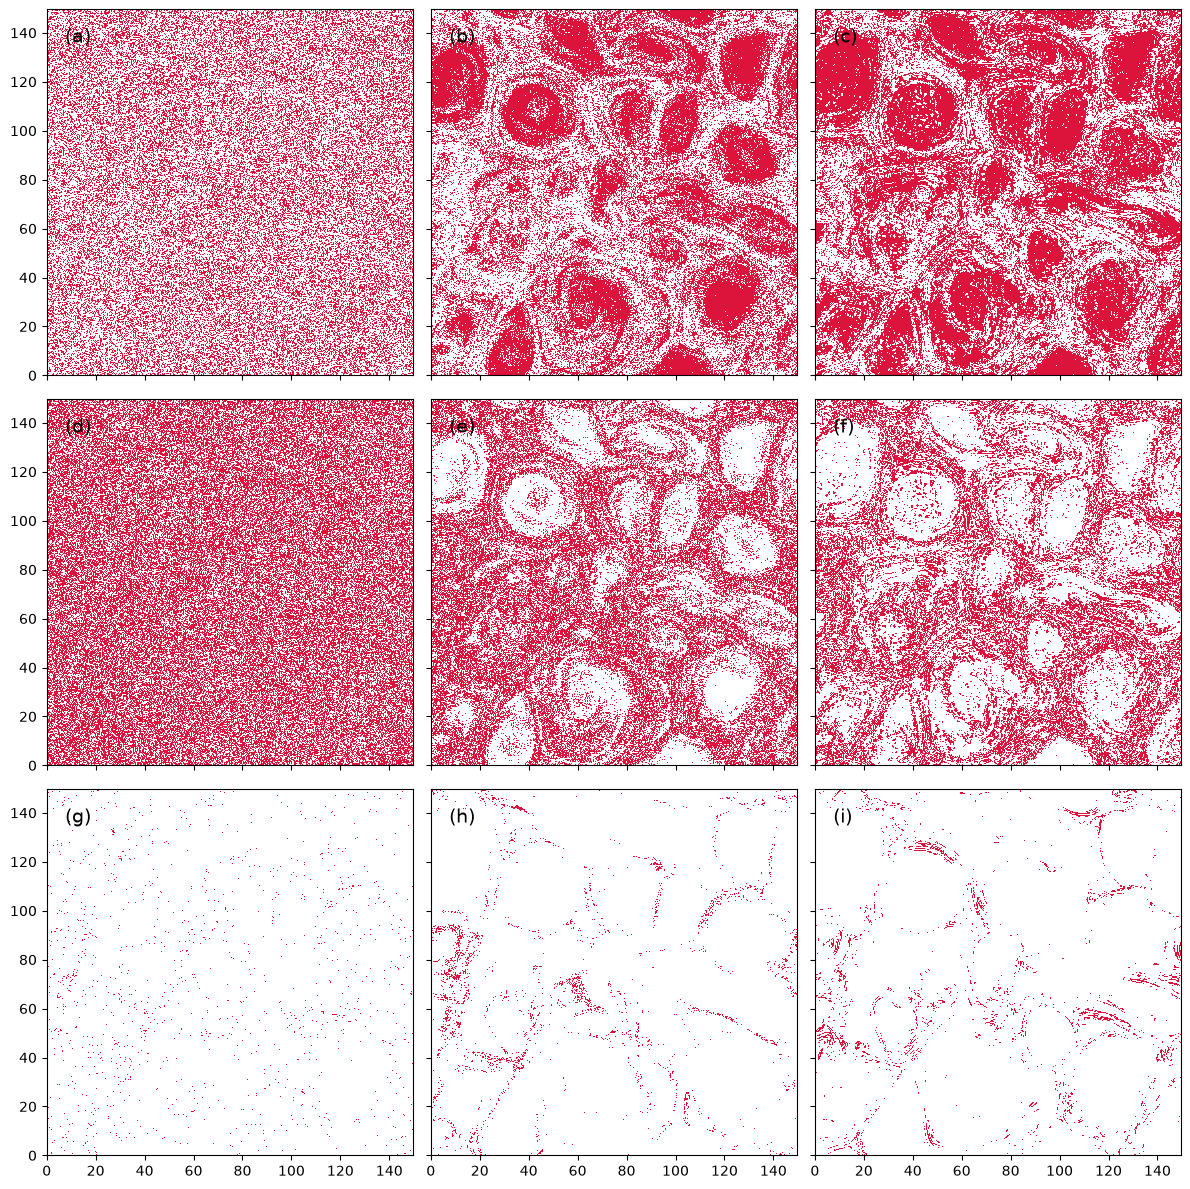

In [ ]:
fig, ax = plt.subplots(3, 3, figsize=(12, 12), sharex=True, sharey=True)

for row in range(3):
    for col in range(3):
        ax[row, col].set_box_aspect(1) 
        ax[row, col].imshow(masked_data[row, col], interpolation = 'nearest', extent = (ds.x[0], ds.x[-1], ds.y[0], ds.y[-1]), cmap=cmap, vmin=0, vmax=1)

        # masked_data[row, col].plot(
        #     ax=ax[row, col],
        #     cmap=cmap,
        #     vmin=0, vmax=1,
        #     add_colorbar=False,
        # )

        ax[row, col].text(
            0.05, 0.95, f'({chr(97 + row * 3 + col)})',
            transform=ax[row, col].transAxes,
            ha='left', va='top',
            fontsize=14,
        )

        ax[row, -1].set_ylabel(f'Region {row + 1}\ny')

plt.tight_layout()